We'll expand the characterization of the baseline microbiome in this notebook to cover all our potential metrics and 

In [1]:
import itertools as it
import os
import textwrap as tw
import warnings
warnings.simplefilter(category=FutureWarning, action='ignore')

import biom
import numpy as np
import pandas as pd
import scipy
import skbio
import statsmodels.formula.api as smf
import statsmodels.api as sms

from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.colors as mpc
from matplotlib.ticker import StrMethodFormatter
import seaborn as sn

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.diversity.actions as q2_div
import qiime2.plugins.feature_table.actions as q2_feature_table
import qiime2.plugins.gemelli.actions as q2_gemelli
import qiime2.plugins.taxa.actions as q2_taxa

rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)

%matplotlib inline

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
warnings.simplefilter(category=FutureWarning, action='ignore')

In [3]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
beta_metrics = ['jaccard', 'braycurtis', 
                'unweighted_unifrac', 'weighted_unifrac']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): c for i, c in enumerate(colors)}

# Wire Frame

In [4]:
def _label_figure(fig, label):
    ax = fig.add_subplot(1,1,1)
    ax.set_position((0.05, 0.05, 0.9, 0.9))
    ax.text(0.5, 0.5, label, ha='center', va='center', size=10)
    ax.xaxis.set_tick_params(left=False, labelleft=False, right=False, labelright=False, length=0, labelsize=0)
    ax.yaxis.set_tick_params(left=False, labelleft=False, right=False, labelright=False, length=0, labelsize=0)


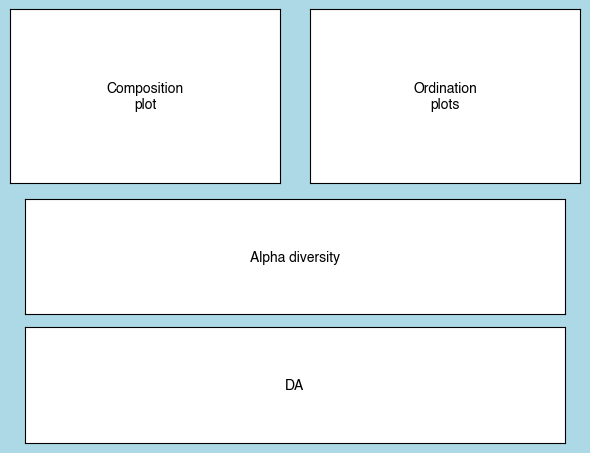

In [5]:
fig = plt.figure(dpi=100,  figsize=(6, 4.5), facecolor='lightblue')
figt, figm, figl = fig.subfigures(3, 1, height_ratios=[1.5, 1, 1], facecolor='None')
figt0, figt1 = figt.subfigures(1, 2, width_ratios=[1, 1], facecolor='None')
_label_figure(figt0, 'Composition\nplot')
_label_figure(figt1, 'Ordination\nplots')
_label_figure(figm, 'Alpha diversity')
_label_figure(figl, 'DA')

# Data

## Metadata 

In [6]:
meta = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta.set_index('sample-id', inplace=True)

In [7]:
meta_bl = meta.loc[meta['timepoint'].isin([0, '0.0'])].copy()
meta_bl_q2 = Metadata(meta_bl)

## Table

### Gene

In [8]:
gene_table_q2 = Artifact.load('final-data/03.amr-tables/megares_table_q2.qza')
gene_taxa_q2 = Artifact.load('final-data/03.amr-tables/megares_taxa_q2.qza')

In [9]:
gene_table_bl_q2, = \
    q2_feature_table.filter_samples(gene_table_q2, metadata=meta_bl_q2)

### Group

In [10]:
group_table_bl_q2, = \
    q2_taxa.collapse(table=gene_table_bl_q2,
                     taxonomy=gene_taxa_q2,
                     level=3)


## Mechnaism

In [11]:
mechanism_table_bl_q2, = \
    q2_taxa.collapse(table=gene_table_bl_q2,
                     taxonomy=gene_taxa_q2,
                     level=2)

In [12]:
group_norm = group_table_bl_q2.view(biom.Table).norm()
group_top = \
    group_norm.collapse(lambda id_, md: 'avg', axis='sample', norm=True)
group_top = group_top.to_dataframe().sort_values('avg', ascending=False)
top_groups = group_top.loc[group_top['avg'] > 0.01]

## Alpha Diversity

In [13]:
alpha_metrics = ['observed_features', 'shannon', 'simpson']
alpha_dir = 'final-data/05.amr-alpha/'
alpha_q2 = {metric: Artifact.load(f'{alpha_dir}/gene_{metric}_2k_avg.qza')
            for metric in alpha_metrics}
alpha = pd.DataFrame({metric: art.view(pd.Series) for metric, art in alpha_q2.items()})
alpha_bl = alpha.loc[meta_bl.index].copy()
obs_feat = alpha_bl['observed_features']
obs_feat.mask(obs_feat - obs_feat.mean() > 2 * obs_feat.std(), inplace=True)
alpha_bl['z_obs_feat'] = \
    (alpha_bl['observed_features'] - obs_feat.mean()) / obs_feat.std()

## Beta Diveristy

In [14]:
beta_dir = 'final-data/07.amr-beta/'
beta_metrics = ['braycurtis', 'jaccard']
beta_dm_q2 = {
    metric: Artifact.load(f'{beta_dir}/gene_{metric}_2K_avg.qza')
    for metric in beta_metrics
}
beta_dm_q2 = {
    metric: q2_div.filter_distance_matrix(dm_q2, metadata=meta_bl_q2).filtered_distance_matrix
    for metric, dm_q2 in beta_dm_q2.items()
}

In [15]:
beta_pc_q2 = {
    metric: q2_div.pcoa(dm_q2, number_of_dimensions=3).pcoa
    for metric, dm_q2 in beta_dm_q2.items()
}

# Composition plot

In [16]:
group_bar = \
    group_norm.filter(lambda v, id_, md: id_ in top_groups.index, 
                      axis='observation')
group_bar = group_bar.to_dataframe().sparse.to_dense()
group_bar = group_bar.loc[top_groups.index].T

group_bar['group'] = meta_bl['abx_code2']
group_bar.sort_values(['group', 'Drugs;Tetracyclines;Tetracycline_resistance_ribosomal_protection_proteins'],
                      ascending=[True, False],
                      inplace=True)
group_bar['x'] = 1 + (~group_bar['group'].duplicated('first')) * 2.5
group_bar['x'] = group_bar['x'].cumsum()
group_bar['x'] = group_bar['x'] - group_bar['x'].min()
group_bar.set_index(['group', 'x'], inplace=True)

In [17]:
group_palette = [mpc.to_hex(c) for c in sn.color_palette('Set2', n_colors=8)]

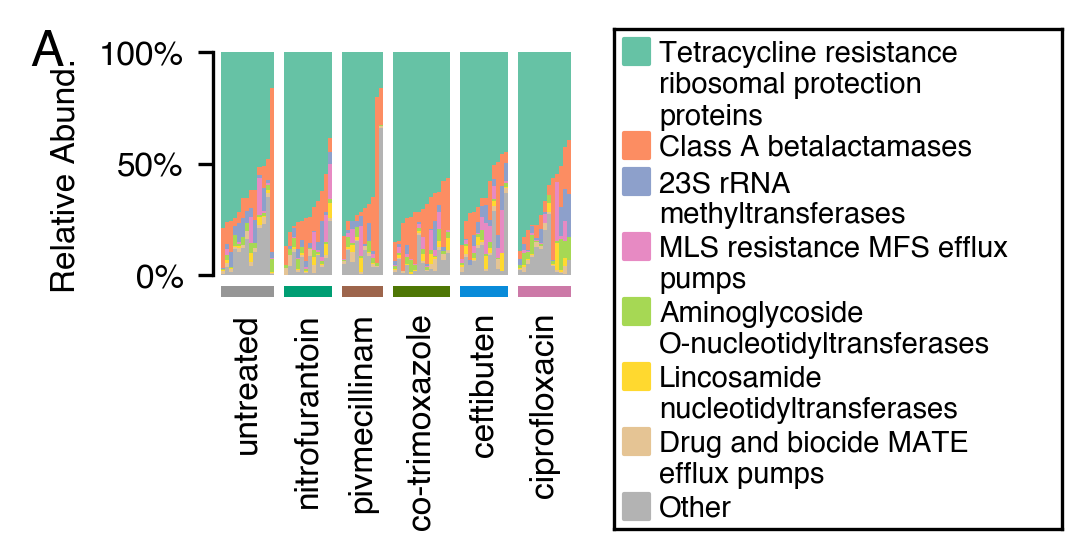

In [18]:
fig = plt.figure(dpi=300, figsize=(3.5, 1.75), facecolor='None', constrained_layout=True)
def _stacked_group_plot(fig, group_palette=group_palette, group_bar=group_bar):
    """
    Makes a stacked barolot
    """
    figx, figl = fig.subfigures(1, 2, width_ratios=[1.2, 1], facecolor='None')

    # Stacked Barplot
    group_barl = group_bar.cumsum(axis=1) - group_bar
    axb = figx.add_subplot(1,1,1, facecolor='None')
    for c, (col_, df) in zip(*(group_palette, group_bar.items())):
        axb.bar(x=df.index.to_frame()['x'],
                bottom=group_barl[col_],
                height=df,
                color=c,
                edgecolor='None',
                width=1)
    axb.bar(x=df.index.to_frame()['x'],
            bottom=group_bar.sum(axis=1),
            height=1-group_bar.sum(axis=1),
            color=group_palette[-1],
            width=1,
            edgecolor='None',
            )
    
    axb.bar(x=df.index.to_frame()['x'],
            bottom=1.05,
            height=0.05,
            color=df.index.to_frame()['group'].replace(abx_colors),
            width=1,
            edgecolor='None',
            )
    axb.set_xticks(df.index.to_frame().reset_index(drop=True).groupby('group')['x'].mean())
    axb.set_xticklabels(abx_order, rotation=90)
    axb.set_xlim(df.index.to_frame()['x'].min() - 2.5, 
                 df.index.to_frame()['x'].max() + 2.5)
    axb.set_ylim(1.1, 0)
    axb.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: '{0:1.0%}'.format(1-x)))
    axb.yaxis.set_tick_params(left=True, labelleft=True, right=False, 
                              labelright=False, labelsize=8)
    axb.xaxis.set_tick_params(bottom=False, labelbottom=True, top=False, 
                              labeltop=False, labelsize=8, length=0)
    axb.set_ylabel('Relative Abund.', size=8)
    axb.set_yticks(np.linspace(0, 1, 3))
    sn.despine(ax=axb, left=False, right=True, top=True, bottom=True, trim=True)

    # Legend
    axl = figl.add_subplot(1,1,1)
    axl.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                              labelright=False, labelsize=0, length=0)
    axl.xaxis.set_tick_params(left=False, labelleft=False, right=False, 
                              labelright=False, length=0, labelsize=0)
    labels = np.hstack([[c.split(';')[-1].replace("_", ' ') 
                         for c in group_bar.columns], 'Other'])
    labels = ['\n'.join(tw.wrap(l, width=25)) for l in labels]
    ypos = np.ones(8) * 1.25 + np.hstack([0, [c.count('\n') 
                                              for c in labels[:-1]]])
    ypos = np.cumsum(ypos)
    ypos = ypos.max() - ypos
    
    axl.scatter(x=np.ones(8) * 0.05, y=ypos, marker='s', c=group_palette)
    axl.set_xlim(0, 1)
    for y, l in zip(*(ypos, labels)):
        axl.text(0.1, y + 0.4, l, size=7, ha='left', va='top')
    # Adds label
    axb.text(axb.get_xlim()[0] - np.diff(axb.get_xlim()) * 0.5,
             axb.get_ylim()[1],
             'A',
             size=12,
             ha='left',
             va='center')
_stacked_group_plot(fig)

# Beta Diversity

## Adonis

We need to write the baseline files so we can run things through R in adonis

In [19]:
baseline_dir = 'final-data/06.baseline_compare/amr'
os.makedirs(baseline_dir, exist_ok=True)
meta_bl.to_csv(f'{baseline_dir}/meta_baseline.tsv',
               sep='\t')
for metric, dm_q2 in beta_dm_q2.items():
    dm_q2.view(skbio.DistanceMatrix).write(f'{baseline_dir}/{metric}_baseline.tsv')

In [20]:
%%bash
Rscript scripts/amr-baseline/baseline_adonis_amr.r

In [21]:
gene_adonis = pd.read_csv(f'{baseline_dir}/amr_bl_adonis_res.tsv',
                          sep='\t',
                          dtype=str)
gene_adonis.set_index(['metric', 'model', 'key_vars'],
                      inplace=True)
gene_adonis = gene_adonis.astype(float)

In [22]:
gene_adonis_f = gene_adonis.xs('full', level='model').copy()
gene_adonis_f = gene_adonis_f.unstack(0)
gene_adonis_f.sort_values([('R2', 'jaccard')], ascending=False, inplace=True)
gene_adonis_f

R2              p_value              nperm        
metric   braycurtis   jaccard braycurtis jaccard braycurtis jaccard
key_vars                                                           
extract    0.102582  0.057766      0.206   0.698      999.0   999.0
abx        0.056347  0.030691      0.540   0.888      999.0   999.0
age        0.005510  0.004312      0.652   0.703      999.0   999.0
diet       0.004239  0.003734      0.782   0.713      999.0   999.0
sex        0.052350  0.002360      0.025   0.896      999.0   999.0

In [23]:
abrev = {'braycurtis': 'bc',
         'unweighted_unifrac': 'uu',
         'weighted_unifrac': 'wu',
         'jaccard': 'jc',
         'rpca': 'rpc',
         'phylo-rpca': 'ppc',
          }
coords = [meta_bl]
coords.extend(
    [pc.view(skbio.OrdinationResults).samples.add_prefix(abrev[metric])
    for metric, pc in beta_pc_q2.items()]
)
coords = pd.concat(axis=1, objs=coords)

perc_exp = pd.concat(axis=0, objs=[
    pc.view(skbio.OrdinationResults).proportion_explained.add_prefix(abrev[metric])
    for metric, pc in beta_pc_q2.items()])

In [24]:
def _plot_adonis_bar(fig, metric):
    ax = fig.add_subplot(1,1,1)
    ax.barh(y=5-np.arange(5),
            left=0,
            width=gene_adonis_f['R2'][metric],
            color='#525252',
           )
    ax.set_yticks(5-np.arange(5))
    ax.set_xlim(0, 0.11)
    ax.set_xticks(np.arange(0, 0.11, 0.05))

    p_vals = gene_adonis_f['p_value'][metric]
    if (p_vals < 0.05).any():
        p_vals = np.floor(-np.log10(p_vals).mask(p_vals > 0.05, 0))
        p_vals = p_vals.astype(int).apply(lambda x: ''.join(['*'] * x))
        for i, (id_, p) in enumerate(p_vals.items()):
            ax.text(y=5 - i, 
                    x=gene_adonis_f.loc[id_, "R2"][metric] + 0.1 * 0.175,
                    s=p,
                    rotation=90,
                    ha='center', 
                    va='center', 
                    size=8)
                    

    
    ax.set_yticklabels(['Extr', 'Abx', 'Sex', "Age", 'Diet'],
                       size=7)
    ax.yaxis.set_tick_params(left=False, labelleft=True, right=False, 
                             labelright=False, labelsize=7, length=0)
    ax.xaxis.set_tick_params(bottom=False, labelbottom=True, top=False, 
                             labeltop=False, labelsize=7, length=0)
    ax.xaxis.grid(True)
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:1.0%}'))
    ax.text(x=np.mean(ax.get_xlim()),
            y=ax.get_ylim()[0] - 0.4 * np.diff(ax.get_ylim()),
            s='Adonis $R^{2}$',
            ha='center',
            va='top', 
            size=8)
    sn.despine(ax=ax, left=True, right=True, top=True, bottom=False)

In [25]:
tick_in = dict(left=True, right=True, labelleft=False, labelright=False, labelsize=0, tickdir='in', length=2.5)
hide_axes = dict(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)
def _ord_plot(fig, pc0, pc1, hue, palette, data, perc_exp):
    """
    Makes an ordination plot
    """
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 4], width_ratios=[4, 1])
    axm = fig.add_subplot(gs[1, 0])
    ax0 = fig.add_subplot(gs[0, 0], sharex=axm, facecolor='None')
    ax1 = fig.add_subplot(gs[1, 1], sharey=axm, facecolor='None')

    scatter_kwargs = dict(edgecolor='None',
                          s=2,)
    box_kwargs = dict(linewidth=0.5,
                      fliersize=0.5)
    
    sn.scatterplot(ax=axm, x=pc0, y=pc1, data=data, hue=hue, palette=palette, 
                   **scatter_kwargs)
    sn.boxplot(ax=ax0, x=pc0, y=hue, palette=palette, data=data, **box_kwargs)
    sn.boxplot(ax=ax1, y=pc1, x=hue,  palette=palette, data=data, **box_kwargs)
    axm.get_legend().set_visible(False)
    axm.xaxis.set_major_locator(ticker.LinearLocator(5))
    axm.xaxis.set_tick_params(**tick_in)
    axm.yaxis.set_major_locator(ticker.LinearLocator(5))
    axm.yaxis.set_tick_params(**tick_in)
    axm.set_xlabel(f'PC 1 ({{{pc0}:1.1%}})'.format(**perc_exp), size=7)
    axm.set_ylabel(f'PC 2 ({{{pc1}:1.1%}})'.format(**perc_exp), size=7)
    
    for ax_ in [ax0.xaxis, ax0.yaxis, ax1.xaxis, ax1.yaxis]:
        ax_.set_tick_params(**hide_axes)
        ax_.get_label().set_visible(False)

    sn.despine(ax=ax0, left=True, right=True, top=True, bottom=True)
    sn.despine(ax=ax1, left=True, right=True, top=True, bottom=True)


In [26]:
extr_names = meta_bl['extraction_no'].unique()
extr_palette = {k: mpc.to_hex(c) for k, c in zip(*(extr_names, sn.color_palette(n_colors=len(extr_names))))}

In [27]:
met_order = [['jaccard', 'jc', 'Jaccard'],
             # ['rpca', 'rpc', 'rPCA'],
             ['braycurtis', 'bc', 'Bray Curtis'],
             ]

In [28]:
def _plot_baseline_pc(figt, figa, figc, metric, prefix, title):
    """
    Plots the ordination results
    """
    pc0 = f'{prefix}0'
    pc1 = f'{prefix}1'
    _ord_plot(figa, pc0, pc1, 'abx_code2', abx_colors, coords, perc_exp)
    # _ord_plot(figb, pc0, pc1, 'extraction_no', extr_palette, coords, perc_exp)
    _plot_adonis_bar(figc, metric)
    axt = figt.add_subplot(1,1,1, facecolor='None')
    axt.set_position((0, 0, 1, 1))
    axt.xaxis.set_tick_params(**hide_axes)
    axt.yaxis.set_tick_params(**hide_axes)
    axt.set_xlim(0, 1)
    axt.set_ylim(0, 1)
    axt.text(0.5, 0.5, title, ha='center', va='center', size=8)
    sn.despine(figt, left=True, right=True, top=True, bottom=True)

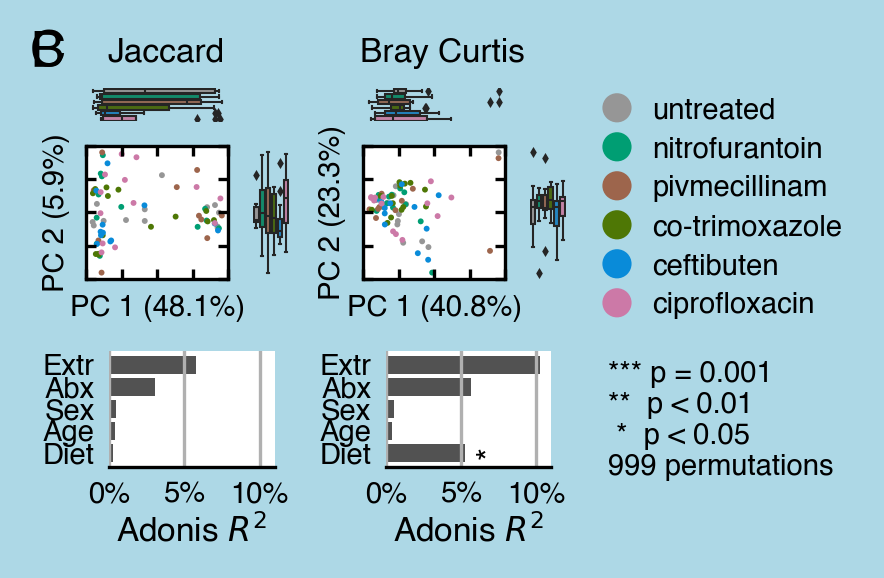

In [29]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(2.75, 1.75), facecolor='lightblue')
def _build_beta_panels(fig):
    """
    Convenience function to mak the beta figure easier
    """
    figs = fig.subfigures(3, 3, height_ratios=[0.15, 1, 0.85], facecolor='None')
    for fig_r, met_info in zip(*(figs.T, met_order)):
        _plot_baseline_pc(*fig_r, *met_info)
    figs[0][0].axes[0].text(figs[0][0].axes[0].get_xlim()[0],
                            np.mean(figs[0][0].axes[0].get_xlim()),
                            'B', size=12, ha='left', va='center')


    axl = figs.T[-1][1].add_subplot(1,1,1, facecolor='None')
    axl.scatter(y=5 - np.arange(0, 6), 
                x=np.ones(6),
                c=colors,
                marker='o',
               )
    axl.set_ylim(-0.5, 5.5)
    axl.set_yticks(5 - np.arange(0, 6))
    axl.set_yticklabels(abx_order)
    axl.xaxis.set_tick_params(**hide_axes)
    axl.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                              labelright=True, labelsize=7, length=0)
    sn.despine(ax=axl, left=True, right=True, top=True, bottom=True)
    
    axa = figs.T[-1][2].add_subplot(1,1,1, facecolor='None')
    axa.set_xlim(0, 1)
    axa.set_ylim(0, 1)
    axa.text(s='*** p = 0.001\n**  p < 0.01\n *  p < 0.05\n999 permutations',
             x=0.05, y=0.95, ha='left', va='top', size=7)
    axa.xaxis.set_tick_params(**hide_axes)
    axa.yaxis.set_tick_params(**hide_axes)
    sn.despine(ax=axa, left=True, right=True, top=True, bottom=True)
    figs[0][0].axes[0].text(figs[0][0].axes[0].get_xlim()[0],
                            np.mean(figs[0][0].axes[0].get_ylim()),
                            'C', size=12, ha='left', va='center')


_build_beta_panels(fig)

# Alpha

In [30]:
meta_a = pd.concat(axis=1, objs=[meta_bl, alpha_bl])
meta_a['age'] = meta_a['age'].astype(float)

In [31]:
def _anova_res_wrap(metric, fit_):
    """
    Pulls out the anova results for the baseline OLS
    """
    anova = sms.stats.anova_lm(fit_)
    anova['n_obs'] = fit_.nobs
    # anova['p'] = anova['df'] + 1
    anova['r2'] = anova['sum_sq'] / anova['sum_sq'].sum()
    anova['metric'] = metric
    
    return anova

In [32]:
alpha_bl_fit = {
    metric: smf.ols(f'{metric} ~ abx_code2 + extraction_no + sex + age + vegetarian',
                    data=meta_a).fit()
    for metric in ['z_obs_feat', 'shannon', 'simpson']
}

In [33]:
alpha_anova_res = pd.concat(
    axis=0, 
    objs=[_anova_res_wrap(metric, fit_) 
          for metric, fit_ in alpha_bl_fit.items()]
)
alpha_anova_res.drop(['Residual'], inplace=True)
alpha_anova_res.set_index('metric', append=True, inplace=True)
alpha_anova_res.sort_values('r2', ascending=False, inplace=True)
alpha_anova_res

df    sum_sq   mean_sq         F    PR(>F)  n_obs  \
              metric                                                           
extraction_no z_obs_feat  6.0  5.954992  0.992499  0.968647  0.454722   72.0   
abx_code2     z_obs_feat  5.0  5.259275  1.051855  1.026577  0.410789   72.0   
              shannon     5.0  1.872645  0.374529  0.669108  0.648384   74.0   
              simpson     5.0  0.075101  0.015020  0.665119  0.651342   74.0   
extraction_no simpson     6.0  0.069051  0.011508  0.509613  0.798664   74.0   
              shannon     6.0  1.450887  0.241815  0.432009  0.854633   74.0   
age           simpson     1.0  0.036090  0.036090  1.598099  0.211144   74.0   
sex           z_obs_feat  1.0  1.123199  1.123199  1.096207  0.299520   72.0   
vegetarian    simpson     1.0  0.019557  0.019557  0.866031  0.355849   74.0   
sex           shannon     1.0  0.395869  0.395869  0.707233  0.403759   74.0   
              simpson     1.0  0.014390  0.014390  0.637202  0.427927   74.0   
vegetarian    shannon     1.0  0.303136  0.303136  0.541563  0.464702   74.0   
age           shannon     1.0  0.211751  0.211751  0.378300  0.540879   74.0   
              z_obs_feat  1.0  0.242805  0.242805  0.236970  0.628270   72.0   
vegetarian    z_obs_feat  1.0  0.016204  0.016204  0.015815  0.900366   72.0   

                                r2  
              metric                
extraction_no z_obs_feat  0.083873  
abx_code2     z_obs_feat  0.074074  
              shannon     0.050260  
              simpson     0.048560  
extraction_no simpson     0.044648  
              shannon     0.038940  
age           simpson     0.023335  
sex           z_obs_feat  0.015820  
vegetarian    simpson     0.012646  
sex           shannon     0.010625  
              simpson     0.009304  
vegetarian    shannon     0.008136  
age           shannon     0.005683  
              z_obs_feat  0.003420  
vegetarian    z_obs_feat  0.000228

In [34]:
var_order = ['extraction_no', 'abx_code2', 'vegetarian', 'age', 'sex']

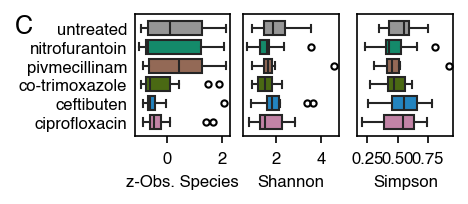

In [35]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3, 1.25))
def _plot_alpha_boxplot(fig):
    """
    A helper function to wrap panel plotting
    """
    gs = fig.add_gridspec(1, 3)
    for i, metric in enumerate(['z_obs_feat', 'shannon', 'simpson']):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharey=ax)
        sn.boxplot(ax=ax, 
                   orient='h',
                   x=metric, 
                   y='abx_code2', 
                   data=meta_a,
                   order=['0', '1', '2', '3', '4', '5'],
                   palette=abx_colors,
                   width=0.75,
                   linewidth=1,
                   flierprops=dict(markersize=3, 
                                   markerfacecolor='None', 
                                   markeredgecolor='k',
                                   marker='o')
                   )
        ax.set_yticks(np.arange(6))
        ax.set_yticklabels(abx_order)
        ax.yaxis.set_tick_params(left=False, labelleft=(i == 0), right=False, 
                                 labelright=False, length=0, labelsize=8)
        ax.yaxis.get_label().set_visible(False)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True, labelsize=8)
        ax.set_ylim(5.75, -0.75, )
    fig.axes[0].set_xlabel('z-Obs. Species', size=8)
    fig.axes[1].set_xlabel('Shannon', size=8)
    fig.axes[2].set_xlabel('Simpson', size=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 1.25,
                     fig.axes[0].get_ylim()[1],
                     'C', size=12, ha='left', va='top')

_plot_alpha_boxplot(fig)

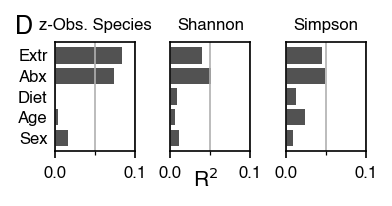

In [36]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(2.5, 1.25))
def _plot_r2_alpha(fig):
    """
    A wrapper function for alpha diveristy correlations?
    """
    gs = fig.add_gridspec(1, 3)
    for i, metric in enumerate(['z_obs_feat', 'shannon', 'simpson']):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharey=ax, sharex=ax)
        ax.yaxis.set_tick_params(left=False, labelleft=(i == 0), right=False, 
                                 labelright=False, labelsize=8, length=0)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True, top=False, 
                                 labeltop=False, labelsize=8)
        ax.barh(y=4 - np.arange(5),
               left=0,
               width=alpha_anova_res.xs(metric, level='metric').loc[var_order, 'r2'],
                color='#525252',
               )
        ax.set_yticks(4 - np.arange(5))
        ax.set_yticklabels(['Extr', 'Abx', 'Diet', 'Age', 'Sex'])
        if i == 1:
            ax.text(x=np.mean(ax.get_xlim()),
                    y=ax.get_ylim()[0] - np.diff(ax.get_ylim()) * 0.15,
                    s='R$^{2}$', 
                    ha='center', 
                    va='top',
                    size=10)
        ax.set_xticks(np.arange(0, 0.11, 0.05), minor=True)
        ax.xaxis.grid(True, which='both')
    fig.axes[0].set_title('z-Obs. Species', size=8)
    fig.axes[1].set_title('Shannon', size=8)
    fig.axes[2].set_title('Simpson', size=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 0.5,
                     fig.axes[0].get_ylim()[1] + np.diff(fig.axes[0].get_ylim()) * 0.25,
                     'D', size=12, ha='left', va='top')
_plot_r2_alpha(fig)

# Differential abundance

In [37]:
genes = gene_table_q2.view(pd.DataFrame).T
genes = genes.loc[genes.sum(axis=1) > 0].copy()
genes_bl = genes[meta_bl.index].copy()
genes_bl['labels'] = gene_taxa_q2.view(pd.Series)

genes_bl.to_csv('final-data/06.baseline_compare/amr/genes_baseline.tsv',
                sep='\t')

In [38]:
%%bash
Rscript scripts/amr-baseline/ancom-bc-amr-bl.r

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: foreach

Attaching package: ‘foreach’

The following objects are masked from ‘package:purrr’:

    accumulate, when

Loading required package: rngtools
There were 50 or more warnings (use warnings() to see the first 50)


In [39]:
amr_bl_res = pd.read_csv('final-data/06.baseline_compare/amr/antibiotic-amr-ancombc-res.tsv',
                         sep='\t',
                         dtype=str)
amr_bl_res.set_index('taxon', inplace=True)
amr_bl_res.replace({"FALSE": '0', 'TRUE': '1'}, inplace=True)
amr_bl_res = amr_bl_res.astype(float).T
amr_bl_resl = amr_bl_res.reset_index().melt(id_vars='index')
amr_bl_resl['abx'] = amr_bl_resl['index'].apply(lambda x: x[-1])
amr_bl_resl['stat'] = amr_bl_resl.apply(
    lambda x: x['index'].replace(x['abx'], '').replace('_abx_code2', ''), 
    axis=1)
amr_bl_resl.replace({'abx': {'B': '1', 'C': '2', 'D': '3', 'E': '4', 'F': '5'}},
                    inplace=True)
amr_bl_resw = amr_bl_resl.pivot(index=['abx', 'taxon'], 
                                columns='stat',
                                values='value')
amr_bl_resw['log_q'] = -np.log10(amr_bl_resw['q'])
amr_bl_resw['log_q'] = amr_bl_resw['log_q'].mask(amr_bl_resw['log_q'] <= 0, 0)

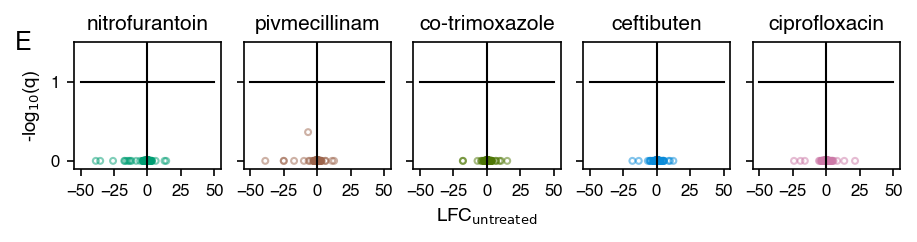

In [40]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 1.5))
def _ancom_bc_plot(fig):
    """
    Builds ANCOM-BC scatter plot
    """
    gs = fig.add_gridspec(1, 5)
    
    for i, (abx, df) in enumerate(amr_bl_resw.groupby('abx', sort=True)):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharex=ax, sharey=ax)
        ax.scatter(x='lfc', y='log_q', data=df,
                   marker='o',
                   s=8,
                   alpha=0.5,
                   color=abx_colors[abx],
                   facecolor='None',
                  )
        ax.set_ylim(-0.1, 1.5)
        ax.plot([0, 0], ax.get_ylim(), color='k', linewidth=1)
        ax.plot([-50, 50], [1, 1], color='k', linewidth=1)
        ax.yaxis.set_tick_params(left=True, labelleft=(i == 0), 
                                 right=False, labelright=False, 
                                 labelsize=8)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True,
                                 labeltop=False, top=False,
                                 labelsize=8)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
        ax.set_xlabel('LFC$_{\\mathrm{untreated}}$', size=9)
        ax.set_ylabel('-log$_{10}$(q)', size=9)
        ax.set_title(abx_order[i + 1], size=10)
        
        ax.yaxis.get_label().set_visible(i == 0)
        ax.xaxis.get_label().set_visible(i == 2)
        ax.xaxis.set_tick_params(labelsize=8)
        ax.yaxis.set_tick_params(labelsize=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 0.4,
                     fig.axes[0].get_ylim()[1],
                     'E', ha='left', va='center', size=12)
_ancom_bc_plot(fig)

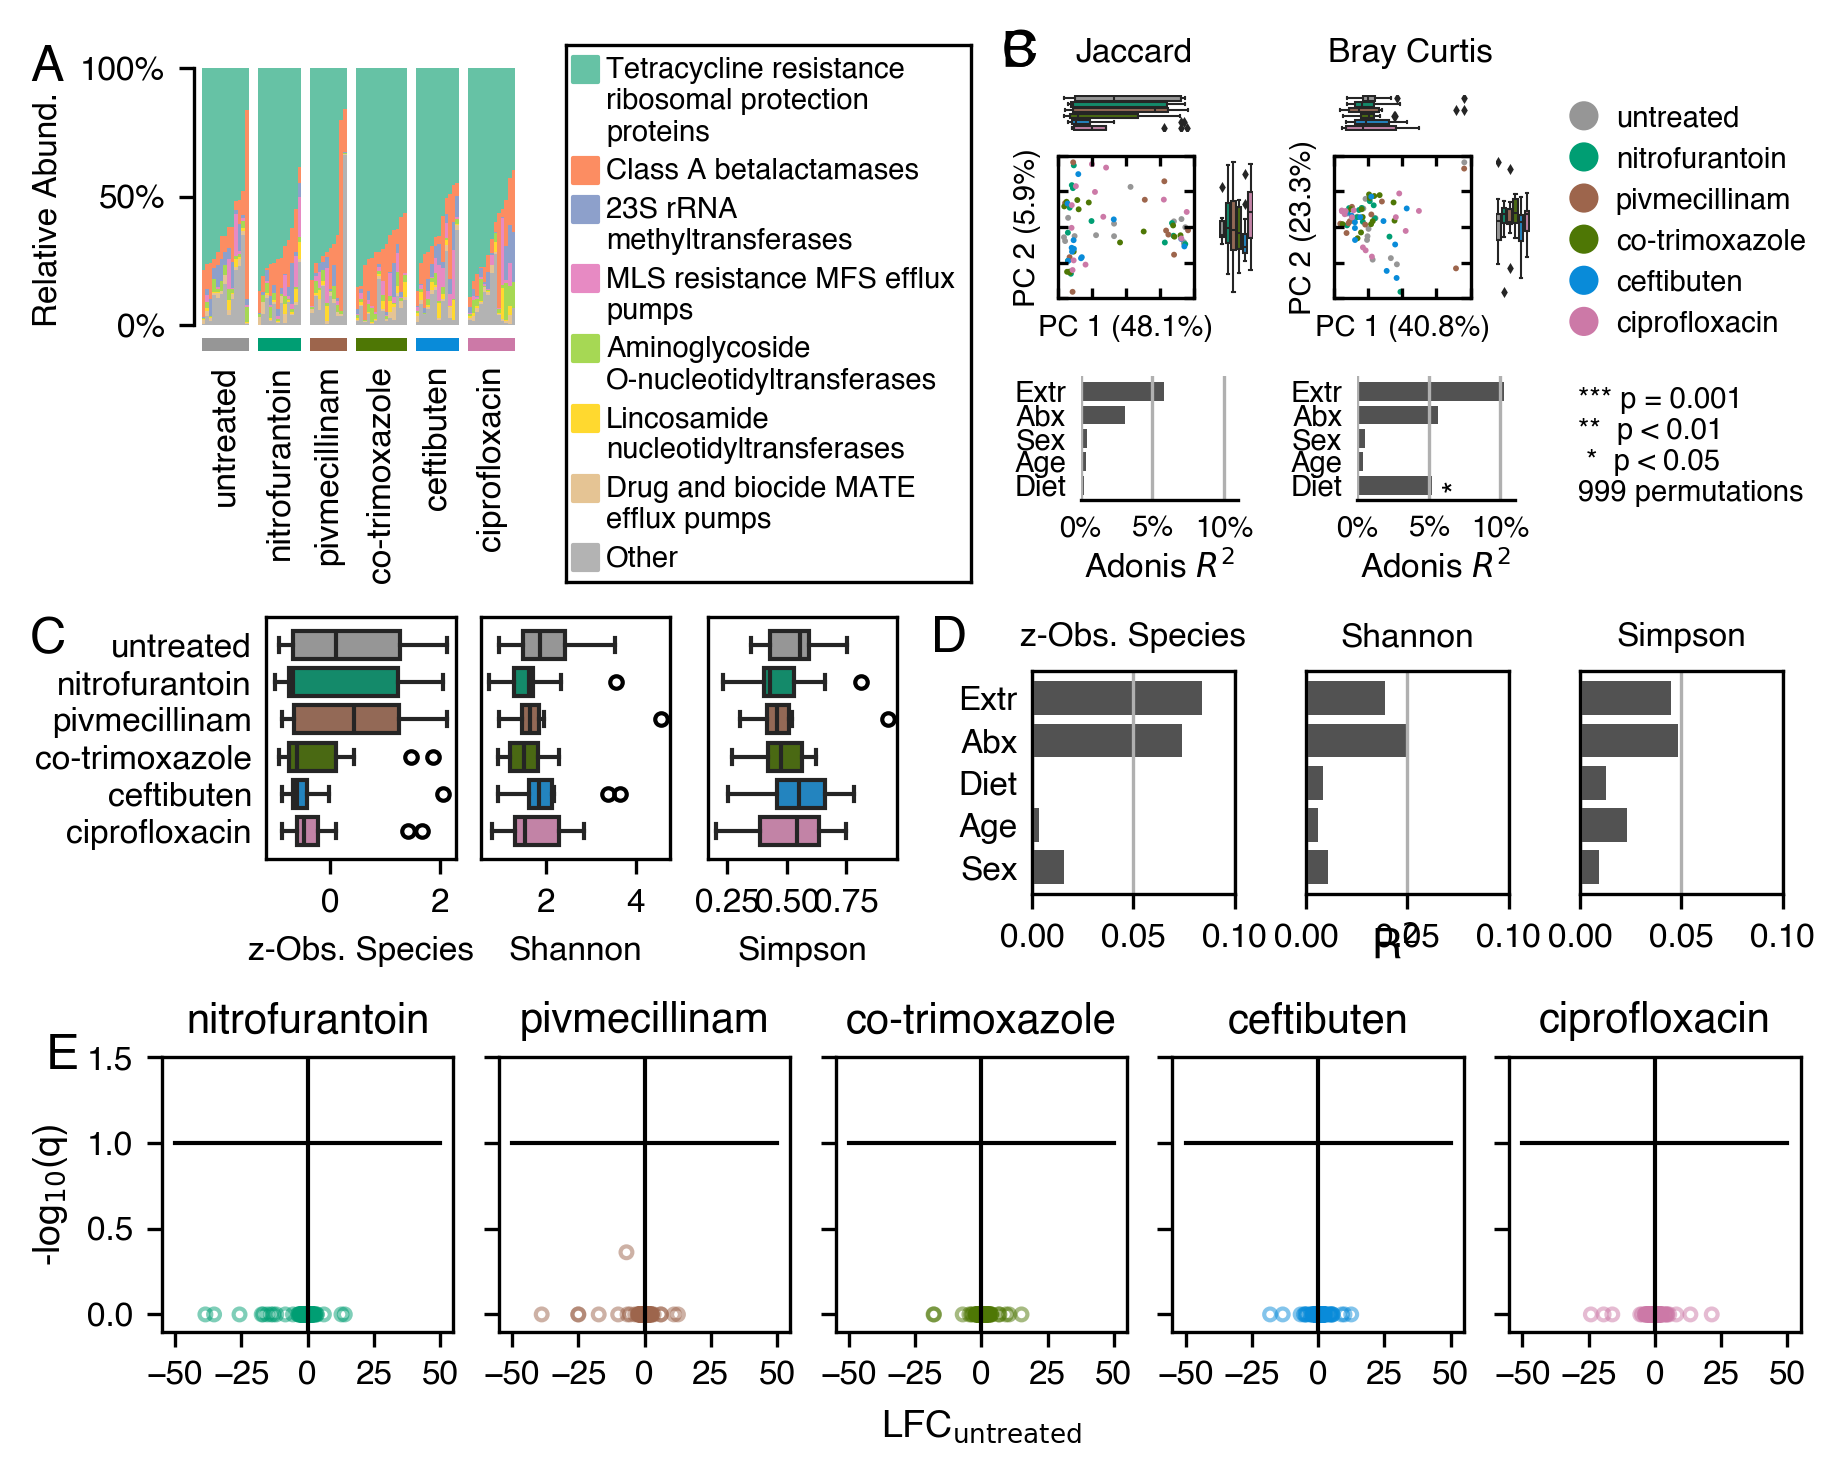

In [41]:
fig = plt.figure(dpi=300,  figsize=(6, 4.75), facecolor='None', constrained_layout=True)
figt, figm, figl = fig.subfigures(3, 1, height_ratios=[1.5, 1, 1.25], facecolor='None')
figt0, figt1 = figt.subfigures(1, 2, width_ratios=[3.25, 2.75], facecolor='None')
figa1, figa2 = figm.subfigures(1, 2, width_ratios=[1, 1], facecolor='None')

_stacked_group_plot(figt0)
_build_beta_panels(figt1)
_plot_alpha_boxplot(figa1)
_plot_r2_alpha(figa2)
_ancom_bc_plot(figl)


**Figure S3. Resistome composition at baseline.** 
(A) The composition of the top antimicrobial resistance (AMR) gene groups at baseline.(B) Ordination plots of Jaccard distance (left), robust Principal components, and Bray Curtis dissimilarity (left to right) at baseline, colored by treatment allocation. (Treatment colors are consistent across figure: gray: untreated, teal: nitrofurantoin, brown: pivmecillinam, green: co-trimoxazole, blue: ceftibuten, pink: ciprofloxacin). Lower panels show the explained variance in the diversity measure in a co-adjusted adonis model. Bars are labeled with significance: * p < 0.05, **p < 0.01, ***p = 0.001, permutative p-value with 999 permutations. (C, D) Alpha diversity at baseline was measured with z-observed species (left), Shannon diversity (middle), and Simpson diversity (right). (C) Distribution of Alpha diversity at baseline by treatment allocation; (D) Variance explained in alpha diversity by each covariate in a co-adjusted linear model; bars are labeled significance: *p < 0.05, **p < 0.01, ***p < 0.001. (E) Differentially abundant AMR genes at baseline by treatment allocation, identified by ANCOM-BC2 adjusted for participant age, sex, vegetarian diet, and the extraction plate. The horizontal line indicates a critical value of q=0.1. 

In [42]:

os.makedirs('./output/figures/', exist_ok=True)
fig.savefig('./output/figures/rigure_S3_amr_baseline.png', dpi=300, facecolor='None')
fig.savefig('./output/figures/figure_S3_amr_baseline.pdf', dpi=300, facecolor='None')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped
